# Module 4: AI Agent Conversation Memory with Redis

We use Groq's API in this module (it's very fast and free tier is generous).

---

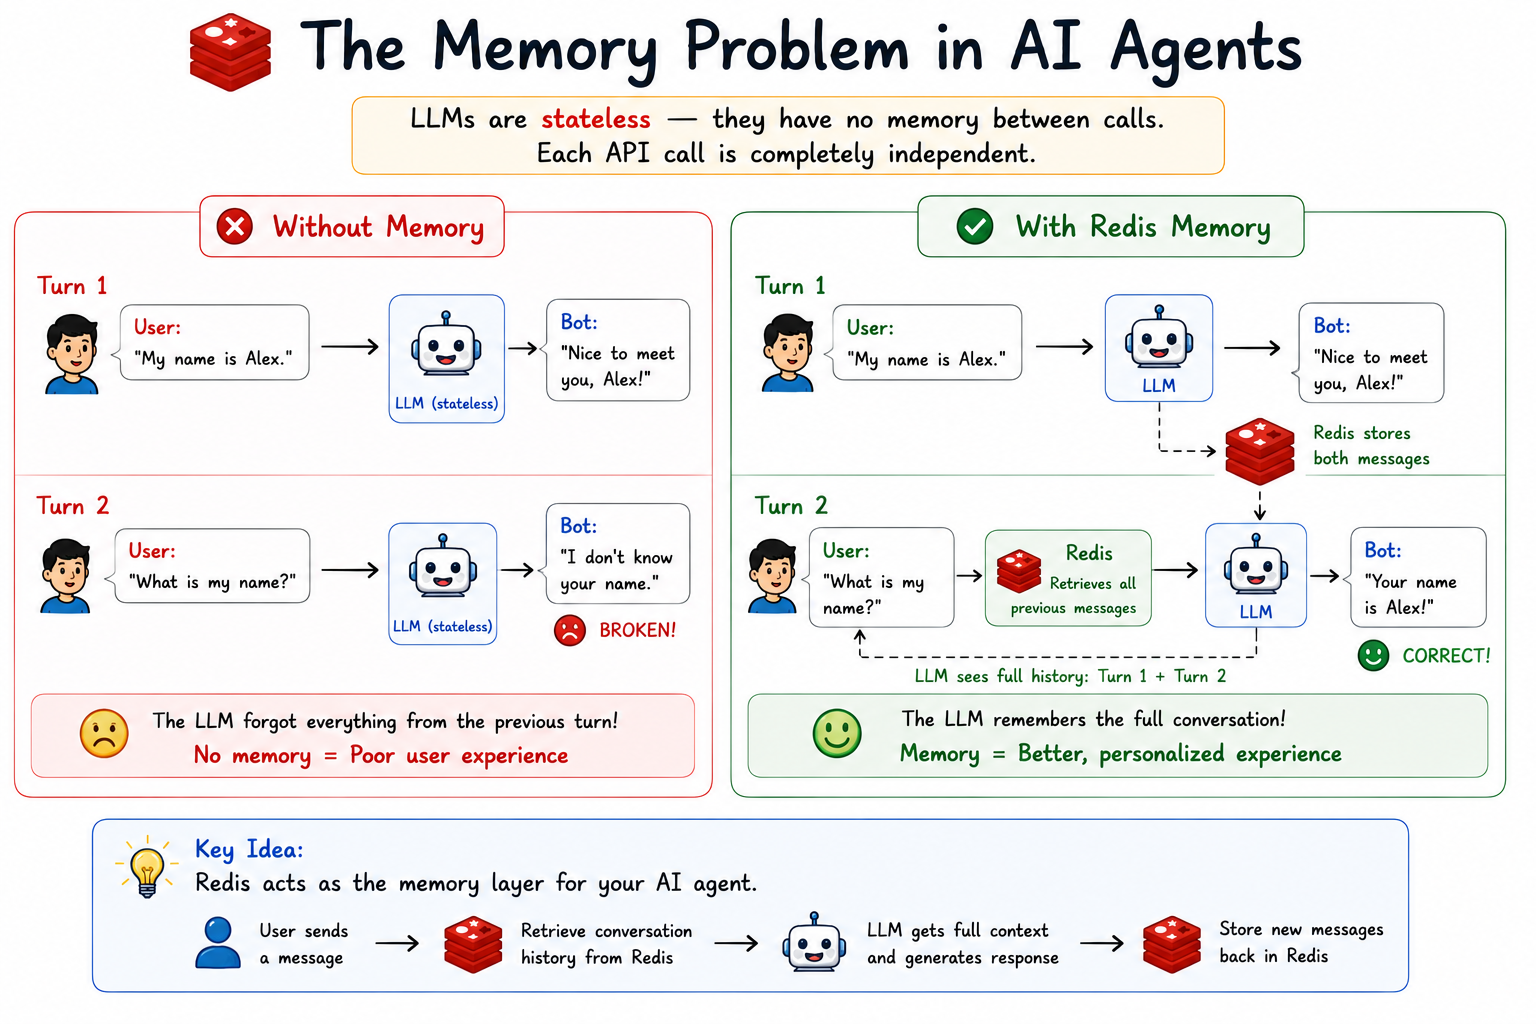

## 1. How Memory Works: The Redis List Approach

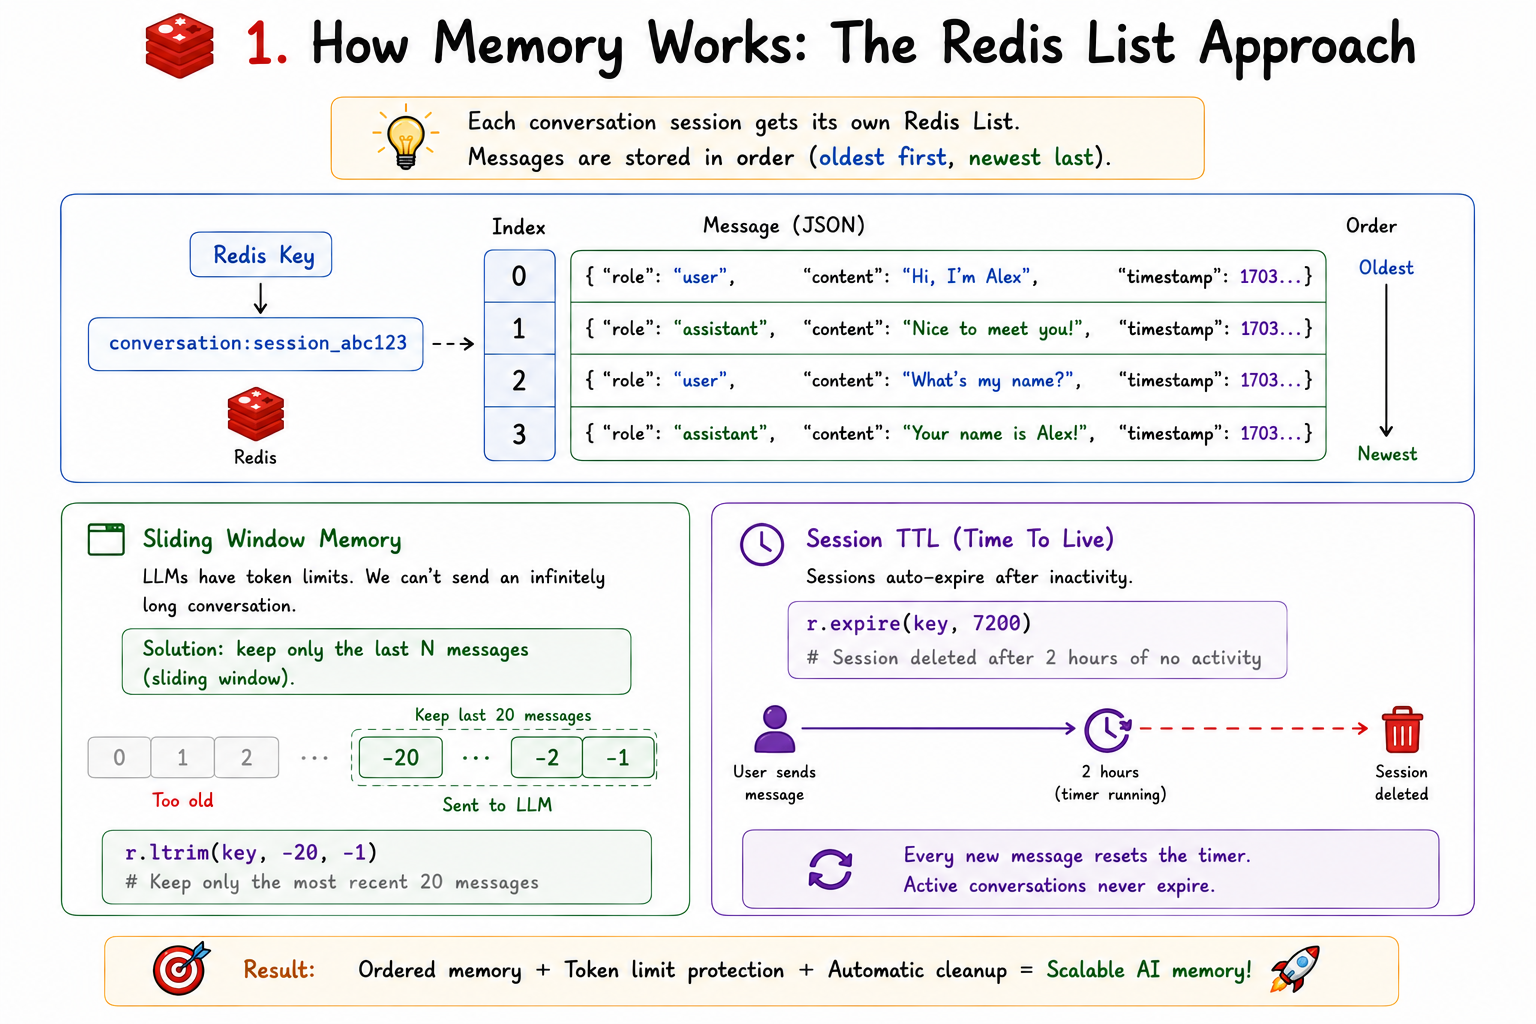

In [20]:
import redis
import json
import time
import os
import uuid
from groq import Groq
from dotenv import load_dotenv

load_dotenv()

r = redis.Redis(
    host=os.getenv('REDIS_HOST', 'localhost'),
    port=int(os.getenv('REDIS_PORT', 6379)),
    decode_responses=True
)

groq_client = Groq(api_key=os.getenv('GROQ_API_KEY'))

r.ping()
print("Redis connected!")
print(f"Groq API key loaded: {'Yes' if os.getenv('GROQ_API_KEY') else 'NO - check your .env file!'}")

Redis connected!
Groq API key loaded: Yes


In [21]:
# ─────────────────────────────────────────────────
# The ConversationMemory class
# Handles all Redis operations for chat history
# ─────────────────────────────────────────────────

class ConversationMemory:
    def __init__(
        self,
        redis_client,
        max_messages: int = 20,
        session_ttl_seconds: int = 7200
    ):
        self.r = redis_client
        self.max_messages = max_messages
        self.session_ttl = session_ttl_seconds

    def _key(self, session_id: str) -> str:
        return f"conversation:{session_id}"

    def add_message(self, session_id: str, role: str, content: str):
        """Append a message to the session's conversation list."""
        key = self._key(session_id)
        message = json.dumps({
            "role": role,
            "content": content,
            "timestamp": time.time()
        })
        self.r.rpush(key, message)
        # Enforce sliding window — keep only the last N messages
        self.r.ltrim(key, -self.max_messages, -1)
        # Reset session TTL on every new message
        self.r.expire(key, self.session_ttl)

    def get_messages(self, session_id: str) -> list:
        """Retrieve all messages in the session, oldest first."""
        key = self._key(session_id)
        raw = self.r.lrange(key, 0, -1)
        return [json.loads(m) for m in raw]

    def get_message_count(self, session_id: str) -> int:
        return self.r.llen(self._key(session_id))

    def clear_session(self, session_id: str):
        """Delete the entire conversation history for a session."""
        self.r.delete(self._key(session_id))

    def get_session_ttl(self, session_id: str) -> int:
        """How many seconds until this session expires."""
        return self.r.ttl(self._key(session_id))


memory = ConversationMemory(r, max_messages=20, session_ttl_seconds=7200)
print("ConversationMemory initialized!")

ConversationMemory initialized!


In [22]:
# ─────────────────────────────────────────────────
# The chat function — ties memory + Groq together
# ─────────────────────────────────────────────────

def chat(
    session_id: str,
    user_message: str,
    system_prompt: str = "You are a helpful, friendly AI assistant. Keep responses concise."
) -> str:
    """Send a message and get a reply, with full conversation history from Redis."""

    # 1. Store the user's message in Redis
    memory.add_message(session_id, "user", user_message)

    # 2. Build the full message list: system prompt + all history
    messages = [{"role": "system", "content": system_prompt}]
    history = memory.get_messages(session_id)
    messages.extend([
        {"role": m["role"], "content": m["content"]}
        for m in history
    ])

    # 3. Call Groq with full history
    response = groq_client.chat.completions.create(
        model="llama-3.1-8b-instant",
        messages=messages,
        max_tokens=400
    )

    reply = response.choices[0].message.content

    # 4. Store the assistant's reply in Redis
    memory.add_message(session_id, "assistant", reply)

    return reply


print("chat() function ready!")

chat() function ready!


## 2. Live Demo — A Real Conversation with Memory

In [23]:
# Start a new session
session_id = "demo_session_001"
memory.clear_session(session_id)  # Start fresh

def show_chat(session_id, user_msg):
    """Send a message and display it nicely."""
    print(f"\n[You]        {user_msg}")
    reply = chat(session_id, user_msg)
    print(f"[Assistant]  {reply}")
    print(f"(History: {memory.get_message_count(session_id)} messages in Redis)")

# Conversation Turn 1
show_chat(session_id, "Hi! My name is Alex and I'm learning about Redis.")


[You]        Hi! My name is Alex and I'm learning about Redis.
[Assistant]  Nice to meet you, Alex. Welcome to Redis. What would you like to know about it? Data structures, use cases, or getting started?
(History: 2 messages in Redis)


In [24]:
# Conversation Turn 2 — will the bot remember?
show_chat(session_id, "What is my name?")


[You]        What is my name?
[Assistant]  Your name is Alex.
(History: 4 messages in Redis)


In [25]:
# Conversation Turn 3 — asking about what we discussed
show_chat(session_id, "What topic am I currently studying?")


[You]        What topic am I currently studying?
[Assistant]  You are currently studying Redis.
(History: 6 messages in Redis)


In [26]:
# Conversation Turn 4 — building on context
show_chat(session_id, "Can you give me a quick summary of what we've talked about so far?")


[You]        Can you give me a quick summary of what we've talked about so far?
[Assistant]  We've had a short conversation. I've:

1. Introduced myself as a friendly AI assistant.
2. Exchanged greetings with you, learning your name is Alex.
3. Discussed Redis, your current topic of study.

That's it so far! Let me know if you have any questions about Redis.
(History: 8 messages in Redis)


In [27]:
# Inspect what's actually stored in Redis
print("=" * 55)
print("WHAT'S STORED IN REDIS FOR THIS SESSION")
print("=" * 55)

messages = memory.get_messages(session_id)
print(f"Total messages stored: {len(messages)}")
print(f"Session TTL: {memory.get_session_ttl(session_id)} seconds remaining")
print()

for i, msg in enumerate(messages):
    ts = time.strftime('%H:%M:%S', time.localtime(msg['timestamp']))
    role_label = f"[{msg['role'].upper():10}]"
    content_preview = msg['content'][:80] + "..." if len(msg['content']) > 80 else msg['content']
    print(f"  {i+1}. {ts} {role_label} {content_preview}")

WHAT'S STORED IN REDIS FOR THIS SESSION
Total messages stored: 8
Session TTL: 7182 seconds remaining

  1. 23:09:59 [USER      ] Hi! My name is Alex and I'm learning about Redis.
  2. 23:09:59 [ASSISTANT ] Nice to meet you, Alex. Welcome to Redis. What would you like to know about it? ...
  3. 23:11:32 [USER      ] What is my name?
  4. 23:11:32 [ASSISTANT ] Your name is Alex.
  5. 23:11:52 [USER      ] What topic am I currently studying?
  6. 23:11:52 [ASSISTANT ] You are currently studying Redis.
  7. 23:12:22 [USER      ] Can you give me a quick summary of what we've talked about so far?
  8. 23:12:22 [ASSISTANT ] We've had a short conversation. I've:

1. Introduced myself as a friendly AI ass...


## 3. Multiple Isolated Sessions

In a real app, many users chat simultaneously. Each gets their own session ID, and their conversations are completely isolated in Redis.

In [28]:
# Simulate two separate users chatting at the same time
# Their histories are completely separate in Redis

session_user1 = "user_session_alice"
session_user2 = "user_session_bob"

memory.clear_session(session_user1)
memory.clear_session(session_user2)

print("=" * 55)
print("ALICE's CONVERSATION")
print("=" * 55)
reply = chat(session_user1, "I'm Alice and I work as a data scientist.")
print(f"[Alice] I'm Alice and I work as a data scientist.")
print(f"[Bot  ] {reply}")

print()
print("=" * 55)
print("BOB's CONVERSATION (separate session)")
print("=" * 55)
reply = chat(session_user2, "Hey! I'm Bob and I love cooking.")
print(f"[Bob  ] Hey! I'm Bob and I love cooking.")
print(f"[Bot  ] {reply}")

print()
print("=" * 55)
print("TESTING ISOLATION — Alice asks, should know her name")
print("=" * 55)
reply = chat(session_user1, "What's my name and what do I do?")
print(f"[Alice] What's my name and what do I do?")
print(f"[Bot  ] {reply}")

print()
print("=" * 55)
print("TESTING ISOLATION — Bob asks, should NOT know about Alice")
print("=" * 55)
reply = chat(session_user2, "Do you know someone named Alice?")
print(f"[Bob  ] Do you know someone named Alice?")
print(f"[Bot  ] {reply}")

print("\n--- Redis session keys ---")
print(f"Alice's key: conversation:{session_user1}  ({memory.get_message_count(session_user1)} msgs)")
print(f"Bob's key  : conversation:{session_user2}  ({memory.get_message_count(session_user2)} msgs)")

ALICE's CONVERSATION
[Alice] I'm Alice and I work as a data scientist.
[Bot  ] Hello Alice. It's nice to meet you. You're a data scientist, huh? What kind of projects have you been working on lately?

BOB's CONVERSATION (separate session)
[Bob  ] Hey! I'm Bob and I love cooking.
[Bot  ] Hi Bob! Nice to meet you. What kind of cooking do you enjoy most? Are you a fan of baking, grilling, or experimenting with new recipes?

TESTING ISOLATION — Alice asks, should know her name
[Alice] What's my name and what do I do?
[Bot  ] Hello Alice, you're a data scientist.

TESTING ISOLATION — Bob asks, should NOT know about Alice
[Bob  ] Do you know someone named Alice?
[Bot  ] I don't have personal knowledge of individuals, Bob. I'm a large language model, I can generate responses based on patterns and contexts, but I don't have personal connections. So, I don't know someone named Alice unless you'd like to tell me about her.

--- Redis session keys ---
Alice's key: conversation:user_session_alice 

## 4. Sliding Window Memory — Handling Long Conversations

LLMs have a context window limit. If we always send the entire history, very long conversations will:
1. Exceed the token limit (API error)
2. Cost more money
3. Get slower as the context grows

The sliding window keeps only the most recent N messages and automatically drops old ones.

In [29]:
small_window_session = "demo_small_window"
small_memory = ConversationMemory(r, max_messages=6, session_ttl_seconds=300)
small_memory.clear_session(small_window_session)

turns = [
    "Turn 1: What is Python?",
    "Turn 2: What is JavaScript?",
    "Turn 3: What is Go?",
    "Turn 4: What is Rust?",
]

for msg in turns:
    small_memory.add_message(small_window_session, "user", msg)
    small_memory.add_message(small_window_session, "assistant", f"Response to: {msg}")

print("Messages added! GO CHECK REDIS DASHBOARD NOW")
print(f"Look for key: conversation:{small_window_session}")


Messages added! GO CHECK REDIS DASHBOARD NOW
Look for key: conversation:demo_small_window


In [30]:
print(f"Total messages in Redis: {small_memory.get_message_count(small_window_session)}")
print("(max was 6, so Turn 1 got pushed out)\n")

oldest = json.loads(r.lrange(f"conversation:{small_window_session}", 0, 0)[0])["content"]
print(f"Oldest message now: '{oldest}'")


Total messages in Redis: 6
(max was 6, so Turn 1 got pushed out)

Oldest message now: 'Turn 2: What is JavaScript?'


In [31]:
print("Final window (only last 6 messages):")
for msg in small_memory.get_messages(small_window_session):
    print(f"  [{msg['role']:10}] {msg['content']}")


Final window (only last 6 messages):
  [user      ] Turn 2: What is JavaScript?
  [assistant ] Response to: Turn 2: What is JavaScript?
  [user      ] Turn 3: What is Go?
  [assistant ] Response to: Turn 3: What is Go?
  [user      ] Turn 4: What is Rust?
  [assistant ] Response to: Turn 4: What is Rust?


In [32]:
memory.clear_session(small_window_session)

## 5. Persistent User Facts (Long-Term Memory)

Short-term memory (conversation history) expires with the session. But some facts about a user should persist across sessions — like their name, preferences, or profile.

We can store these as Redis Hashes with a longer or no TTL.

In [33]:
class UserProfile:
    """Persistent user facts stored in Redis Hashes. No auto-expiry."""

    def __init__(self, redis_client):
        self.r = redis_client

    def _key(self, user_id: str) -> str:
        return f"profile:{user_id}"

    def set_fact(self, user_id: str, field: str, value: str):
        self.r.hset(self._key(user_id), field, value)

    def get_fact(self, user_id: str, field: str) -> str:
        return self.r.hget(self._key(user_id), field) or ""

    def get_all_facts(self, user_id: str) -> dict:
        return self.r.hgetall(self._key(user_id))

    def delete_fact(self, user_id: str, field: str):
        self.r.hdel(self._key(user_id), field)

    def clear(self, user_id: str):
        self.r.delete(self._key(user_id))


def chat_with_profile(
    session_id: str,
    user_id: str,
    user_message: str,
    profile: UserProfile
) -> str:
    """Chat that includes the user's persistent profile in the system prompt."""
    facts = profile.get_all_facts(user_id)

    if facts:
        facts_text = "\n".join([f"- {k}: {v}" for k, v in facts.items()])
        system_prompt = f"""You are a helpful AI assistant.

Known facts about this user:
{facts_text}

Use these facts naturally in your responses when relevant."""
    else:
        system_prompt = "You are a helpful AI assistant."

    return chat(session_id, user_message, system_prompt)


profile = UserProfile(r)

# Store some facts about the user
profile.set_fact("user_alex", "name", "Alex")
profile.set_fact("user_alex", "role", "Machine Learning Engineer")
profile.set_fact("user_alex", "experience", "3 years")
profile.set_fact("user_alex", "preferred_language", "Python")

print("Stored user profile:")
for k, v in profile.get_all_facts("user_alex").items():
    print(f"  {k}: {v}")

Stored user profile:
  name: Alex
  role: Machine Learning Engineer
  experience: 3 years
  preferred_language: Python


In [34]:
# Now start a NEW session — profile persists even though conversation is fresh
new_session = "alex_new_session"
memory.clear_session(new_session)

print("NEW SESSION — conversation history is empty")
print("But the profile is still in Redis from before!")
print()

questions = [
    "What should I focus on to improve as an ML engineer?",
    "Can you recommend a Redis caching pattern that works well with Python?",
]

for q in questions:
    reply = chat_with_profile(new_session, "user_alex", q, profile)
    print(f"[You]  {q}")
    print(f"[Bot]  {reply[:300]}")
    print()

# Cleanup
profile.clear("user_alex")
memory.clear_session(new_session)
memory.clear_session(session_id)
memory.clear_session(session_user1)
memory.clear_session(session_user2)

NEW SESSION — conversation history is empty
But the profile is still in Redis from before!

[You]  What should I focus on to improve as an ML engineer?
[Bot]  As a 3-year experienced Machine Learning Engineer, Alex, you've likely gained a solid foundation in the fundamentals of ML. To continue improving and staying up-to-date with the rapidly evolving field, here are some key areas to focus on:

1. **Deep Learning**: With the increasing popularity of deep

[You]  Can you recommend a Redis caching pattern that works well with Python?
[Bot]  Redis is a popular in-memory data store that can be effectively used as a caching layer in Python applications. Here's a recommended Redis caching pattern using Python:

**Pattern:** Cache-Aside Pattern with Redis Expiration

**Components:**

1. **Redis Client**: Use the `redis` library to establish

